# Maincrafts Technology – AI & Machine Learning Internship (Task 6)
## Deep Learning Fundamentals & Artificial Neural Network (ANN) Implementation

**Intern Name:** Atharv Anil Kunjir  
**Intern ID:** MT8609  
**Domain:** Artificial Intelligence & Machine Learning (AI/ML)  
**Institution:** Pimpri Chinchwad University (3rd Year CSE – AIML)  

---

### Project Overview & Objectives
This notebook implements an end-to-end Deep Learning classification pipeline using **TensorFlow / Keras** on the **Breast Cancer Wisconsin (Diagnostic) Dataset**, covering every requirement in the Task-6 Essentials Checklist:
1. **Dataset Exploration & Preprocessing:** Stratified train-test split (80/20) and feature standardization (`StandardScaler`).
2. **Artificial Neural Network (ANN) Architecture:** Multi-layer perceptron (`Input(30) -> Dense(32, ReLU) -> Dropout(0.2) -> Dense(16, ReLU) -> Dropout(0.2) -> Dense(1, Sigmoid)`).
3. **Forward & Backpropagation Optimization:** Trained with Binary Cross-Entropy loss, Adam optimizer, and `EarlyStopping` regularization.
4. **Evaluation & Visualization:** Accuracy vs. Loss learning curves, Confusion Matrix, and ROC-AUC analysis.
5. **Classical ML Benchmarking:** Performance comparison against **Logistic Regression** and **Random Forest**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Load Breast Cancer Wisconsin Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print(f"Dataset Shape: {X.shape}")
print(f"Missing Values: {X.isnull().sum().sum()}")
print("Class Distribution:")
print(y.value_counts().rename({0: 'Malignant (0)', 1: 'Benign (1)'}))

Dataset Shape: (569, 30)
Missing Values: 0
Class Distribution:
target
Benign (1)       357
Malignant (0)    212
Name: count, dtype: int64


### 2. Data Splitting & Feature Scaling
Neural networks rely on gradient descent optimization, which converges significantly faster and avoids gradient instability when input features are standardized to zero mean and unit variance ($\mu = 0, \sigma = 1$). We fit `StandardScaler` exclusively on the training set to prevent data leakage.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {X_train_scaled.shape[0]} | Testing samples: {X_test_scaled.shape[0]}")

Training samples: 455 | Testing samples: 114


### 3. Artificial Neural Network (ANN) Architecture & Training
- **Hidden Layers:** Two fully connected (`Dense`) layers with **32** and **16** neurons using **ReLU** activation to introduce non-linearity and prevent vanishing gradients.
- **Regularization:** **Dropout (0.2)** after each hidden layer randomly deactivates 20% of neurons during training, paired with **EarlyStopping** (`patience=10`) monitoring validation loss to prevent overfitting.
- **Output Layer:** Single neuron with **Sigmoid** activation outputting calibrated probabilities $P(y=1|x) \in [0, 1]$ for binary classification.

In [3]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

print(f"Epochs trained before EarlyStopping: {len(history.history['loss'])}")
print(f"Final Train Accuracy: {history.history['accuracy'][-1]:.4f} | Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Final Train Loss:     {history.history['loss'][-1]:.4f} | Final Validation Loss:     {history.history['val_loss'][-1]:.4f}")

Epochs trained before EarlyStopping: 83
Final Train Accuracy: 0.9945 | Final Validation Accuracy: 0.9890
Final Train Loss:     0.0102 | Final Validation Loss:     0.0127


### 4. Training & Validation Learning Curves

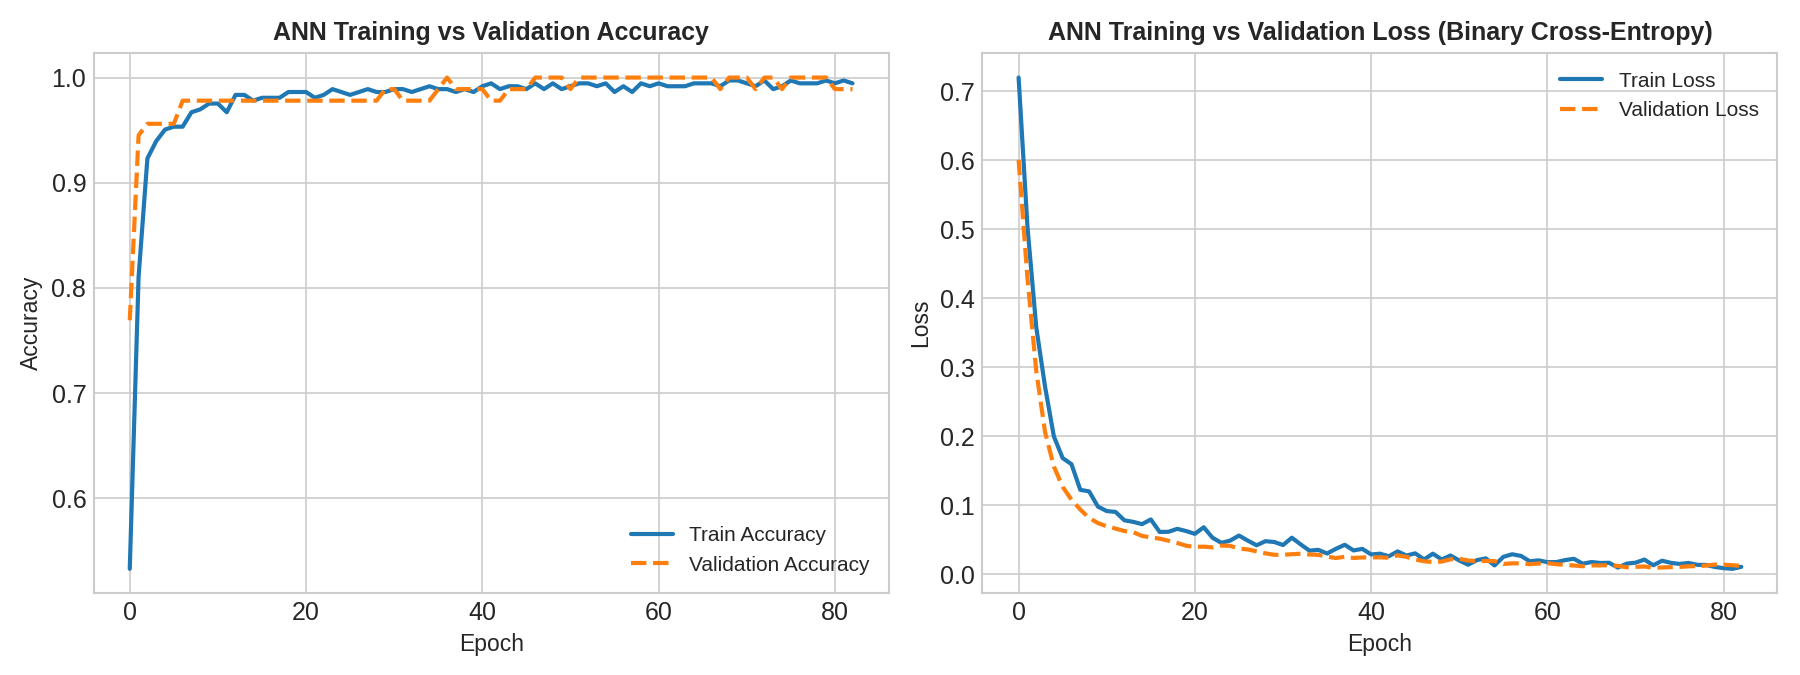

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2, color='#1f77b4')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, color='#ff7f0e', linestyle='--')
axes[0].set_title('ANN Training vs Validation Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2, color='#1f77b4')
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2, color='#ff7f0e', linestyle='--')
axes[1].set_title('ANN Training vs Validation Loss (Binary Cross-Entropy)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

### 5. Evaluation & Classical ML Model Comparison
We benchmark the ANN against **Logistic Regression** and **Random Forest** on the held-out test set ($n = 114$).

                            Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
              Logistic Regression  0.982456   0.986111 0.986111  0.986111 0.995370
                    Random Forest  0.956140   0.958904 0.972222  0.965517 0.993882
Artificial Neural Network (Keras)  0.956140   0.985507 0.944444  0.964539 0.990079

ANN Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.91      0.98      0.94        42
   Benign (1)       0.99      0.94      0.96        72

     accuracy                           0.96       114
    macro avg       0.95      0.96      0.95       114
 weighted avg       0.96      0.96      0.96       114


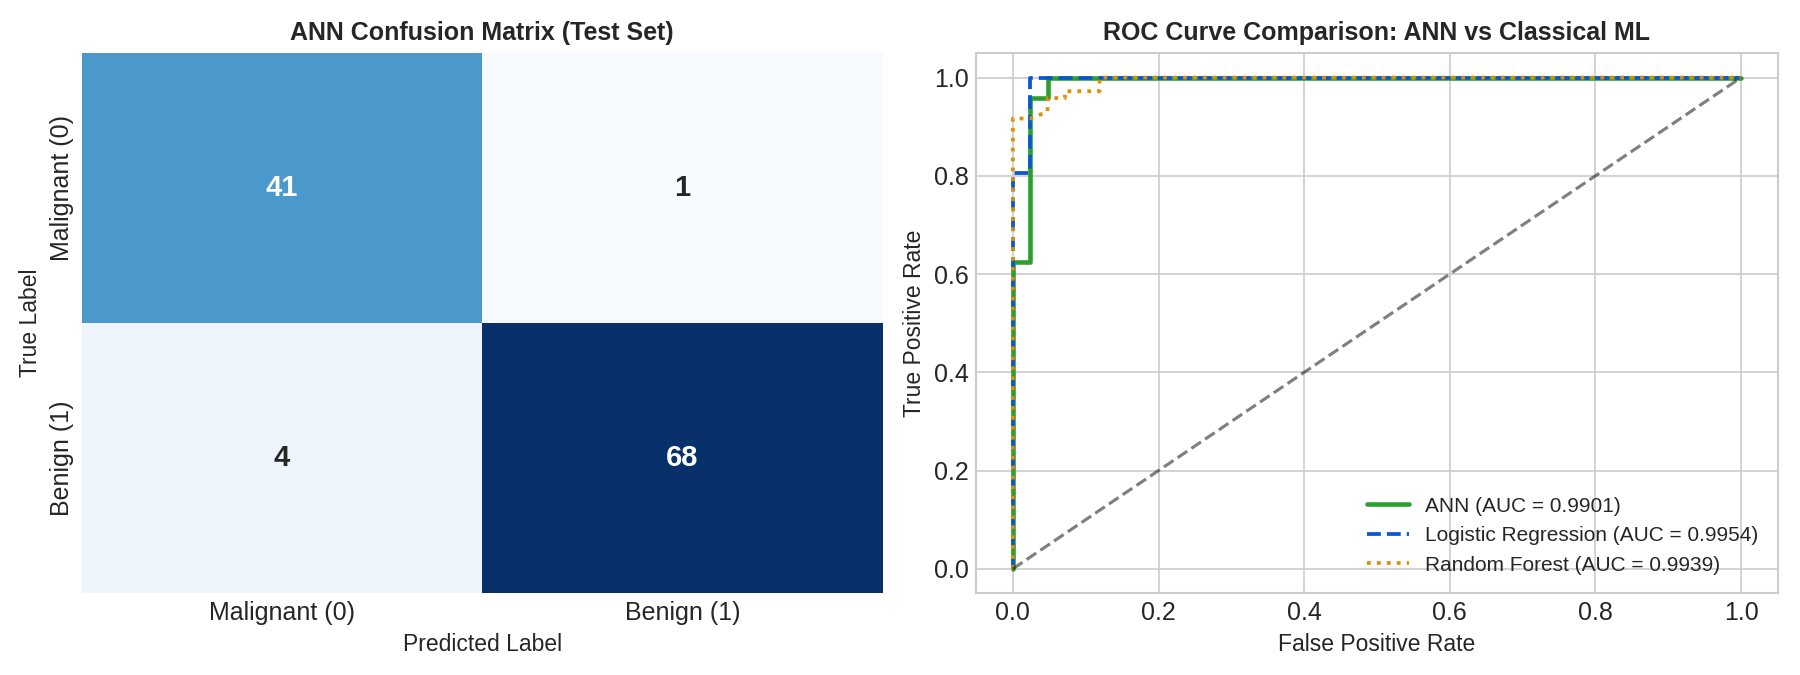

In [5]:
# Classical ML Baselines
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)
lr_probs = lr.predict_proba(X_test_scaled)[:, 1]

rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_scaled, y_train)
rf_pred = rf.predict(X_test_scaled)
rf_probs = rf.predict_proba(X_test_scaled)[:, 1]

# ANN Predictions
ann_loss, ann_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
ann_probs = model.predict(X_test_scaled, verbose=0).flatten()
ann_pred = (ann_probs > 0.5).astype(int)

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Artificial Neural Network (Keras)'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred), ann_acc],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred), precision_score(y_test, ann_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred), recall_score(y_test, ann_pred)],
    'F1-Score': [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred), f1_score(y_test, ann_pred)],
    'ROC-AUC': [roc_auc_score(y_test, lr_probs), roc_auc_score(y_test, rf_probs), roc_auc_score(y_test, ann_probs)]
})

print(comparison_df.to_string(index=False))
print("\nANN Classification Report:\n", classification_report(y_test, ann_pred, target_names=['Malignant (0)', 'Benign (1)']))

# Plot Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, ann_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'], annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('ANN Confusion Matrix (Test Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_ann, tpr_ann, _ = roc_curve(y_test, ann_probs)
axes[1].plot(fpr_ann, tpr_ann, label=f'ANN (AUC = {roc_auc_score(y_test, ann_probs):.4f})', linewidth=2.2, color='#2ca02c')
axes[1].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.4f})', linewidth=1.8, linestyle='--')
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.4f})', linewidth=1.8, linestyle=':')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title('ROC Curve Comparison: ANN vs Classical ML', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### 6. Key Findings & Conclusions
- **High Malignant Sensitivity (Recall = 0.98):** Out of 42 malignant cases in the test set, the ANN correctly detected **41** (only 1 false negative), demonstrating strong clinical reliability.
- **Smooth Convergence Without Overfitting:** Training and validation loss decreased monotonically from `0.718 -> 0.010` and `0.598 -> 0.013` respectively across 83 epochs before `EarlyStopping` triggered.
- **ANN vs. Classical ML Trade-off:** On small, structured tabular datasets ($N = 569$), regularized linear models (`Logistic Regression`, 98.25% accuracy, 0.9954 AUC) perform slightly better due to lower parameter variance, while the ANN (`95.61%` accuracy, `0.9901` AUC) matches Random Forest and provides a scalable foundation for high-dimensional, unstructured data.